# Proyek Analisis Data: Bike Sharing Datase
- **Nama:** Adyuda Ghiffari Ramadhan
- **Email:** adyuda21@gmail.com
- **ID Dicoding:** adyuda_ghiffari

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan non-hari kerja selama Januari 2011–Desember 2012, dan kapan jam puncak permintaan pada masing-masing kelompok?
- **Pertanyaan 2:** Bagaimana rata-rata jumlah penyewaan sepeda harian berbeda antar kategori kondisi cuaca selama Januari 2011–Desember 2012, dan berapa persentase perbedaannya dibandingkan dengan kategori cuaca cerah?

## Import Semua Packages/Library yang Digunakan

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Data Wrangling

### Gathering Data

#### Load df ...

In [3]:
# Load dataset
day_df = pd.read_csv("/content/drive/MyDrive/Bootcamp DBS/submission fundamental analisis data/submission/data/day.csv")
hour_df = pd.read_csv("/content/drive/MyDrive/Bootcamp DBS/submission fundamental analisis data/submission/data/hour.csv")

# Menampilkan ukuran dataset
print("Day Dataset:", day_df.shape)
print("Hour Dataset:", hour_df.shape)

# Menampilkan 5 data pertama
display(day_df.head())
display(hour_df.head())

Day Dataset: (731, 16)
Hour Dataset: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Day Dataset (day_df) memiliki 731 baris dan 16 kolom yang merepresentasikan data penyewaan sepeda harian.
- Hour Dataset (hour_df) memiliki 17.379 baris dan 17 kolom yang merepresentasikan data penyewaan sepeda per jam.

### Assessing Data

#### Identifying ... problem

In [4]:
# Memeriksa kualitas data pada kedua dataset

datasets = {
    "Day Dataset": day_df,
    "Hour Dataset": hour_df
}

for name, df in datasets.items():
    print(f"\n{'=' * 40}")
    print(name)
    print(f"{'=' * 40}")

    # 1. Memeriksa missing values
    print("\nMissing Values:")
    print(df.isnull().sum()[df.isnull().sum() > 0])

    # 2. Memeriksa duplicated rows
    print("\nJumlah Duplikasi:", df.duplicated().sum())

    # 3. Memeriksa tipe data
    print("\nTipe Data:")
    print(df.dtypes)

    # 4. Memeriksa konsistensi jumlah penyewaan
    mismatch = (
        df["cnt"] != df["casual"] + df["registered"]
    ).sum()

    print("\nJumlah data cnt yang tidak konsisten:", mismatch)

    # 5. Memeriksa calon outlier menggunakan IQR
    Q1 = df["cnt"].quantile(0.25)
    Q3 = df["cnt"].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df["cnt"] < lower_bound) |
        (df["cnt"] > upper_bound)
    ).sum()

    print("Jumlah calon outlier pada cnt:", outliers)


Day Dataset

Missing Values:
Series([], dtype: int64)

Jumlah Duplikasi: 0

Tipe Data:
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

Jumlah data cnt yang tidak konsisten: 0
Jumlah calon outlier pada cnt: 0

Hour Dataset

Missing Values:
Series([], dtype: int64)

Jumlah Duplikasi: 0

Tipe Data:
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: ob

**Steps to Take:**
- Konversi tipe data tanggal: Mengubah kolom dteday pada day_df dan hour_df dari object menjadi datetime agar dapat digunakan untuk analisis berdasarkan waktu.
- Pemeriksaan calon outlier: Memeriksa 505 observasi pada kolom cnt di hour_df yang berada di luar batas IQR. Observasi tersebut perlu ditinjau lebih lanjut dan tidak langsung dihapus karena dapat merepresentasikan permintaan penyewaan yang memang tinggi.
- Mempertahankan data yang valid: Karena tidak ditemukan missing value, duplikasi, maupun ketidaksesuaian antara cnt dan penjumlahan casual serta registered, tidak diperlukan penghapusan atau koreksi data untuk masalah-masalah tersebut.
- Menyiapkan label kategori: Memberikan label yang mudah dipahami pada kode kategori seperti season, weathersit, dan weekday saat dibutuhkan untuk visualisasi dan interpretasi hasil analisis.

**Insight:** (Opsional)
- Kelengkapan data: Kedua dataset tidak memiliki missing value, sehingga tidak diperlukan imputasi atau penghapusan data akibat nilai yang kosong.
- Keunikan data: Tidak ditemukan baris duplikat pada kedua dataset berdasarkan pemeriksaan seluruh kolom.
- Konsistensi jumlah penyewaan: Seluruh observasi pada kedua dataset memenuhi persamaan cnt = casual + registered, sehingga tidak ditemukan ketidaksesuaian pada total penyewaan.
- Tipe data tanggal: Kolom dteday pada kedua dataset masih bertipe object dan perlu dikonversi menjadi datetime sebelum analisis temporal dilakukan.
- Calon outlier: Metode IQR tidak mengidentifikasi calon outlier pada day_df, sedangkan pada hour_df ditemukan 505 observasi di luar batas IQR. Temuan ini perlu ditinjau lebih lanjut karena nilai ekstrem belum tentu menunjukkan kesalahan data.

### Cleaning Data

#### Fixing ... problem

In [5]:
# 1. Mengubah tipe data tanggal
day_df["dteday"] = pd.to_datetime(
    day_df["dteday"],
    errors="coerce"
)

hour_df["dteday"] = pd.to_datetime(
    hour_df["dteday"],
    errors="coerce"
)

# 2. Memverifikasi hasil cleaning
print("Day Dataset")
print("Tipe data tanggal:", day_df["dteday"].dtype)
print("Tanggal invalid:", day_df["dteday"].isna().sum())

print("\nHour Dataset")
print("Tipe data tanggal:", hour_df["dteday"].dtype)
print("Tanggal invalid:", hour_df["dteday"].isna().sum())

# 3. Memastikan jumlah data tetap
print("\nUkuran Day Dataset:", day_df.shape)
print("Ukuran Hour Dataset:", hour_df.shape)

Day Dataset
Tipe data tanggal: datetime64[ns]
Tanggal invalid: 0

Hour Dataset
Tipe data tanggal: datetime64[ns]
Tanggal invalid: 0

Ukuran Day Dataset: (731, 16)
Ukuran Hour Dataset: (17379, 17)


**Insight:** (Opsional)
- Perbaikan tipe data: Kolom dteday pada kedua dataset berhasil dikonversi dari tipe object menjadi datetime64[ns]. Perubahan ini memungkinkan analisis berdasarkan tanggal dan waktu dilakukan dengan lebih tepat.
- Kelengkapan data: Tidak ditemukan tanggal invalid setelah proses konversi, sehingga seluruh observasi tetap dapat digunakan.
- Mempertahankan integritas data: Jumlah baris dan kolom pada kedua dataset tidak berubah karena tidak ditemukan missing value maupun duplikasi pada tahap assessment.
- Penanganan calon outlier: Sebanyak 505 observasi pada hour_df yang berada di luar batas IQR tidak dihapus secara otomatis. Nilai tersebut masih perlu diperiksa berdasarkan konteks waktu dan pola permintaan karena nilai ekstrem belum tentu merupakan kesalahan data.

## Exploratory Data Analysis (EDA)

### Explore ...

In [6]:
# 1. Melihat pola penyewaan berdasarkan jam dan jenis hari
hourly_summary = (
    hour_df.groupby(["workingday", "hr"])["cnt"]
    .mean()
    .reset_index()
)

hourly_summary["jenis_hari"] = (
    hourly_summary["workingday"]
    .map({0: "Hari non-kerja", 1: "Hari kerja"})
)

# Mencari jam dengan rata-rata penyewaan tertinggi
peak_hours = hourly_summary.loc[
    hourly_summary.groupby("workingday")["cnt"].idxmax(),
    ["jenis_hari", "hr", "cnt"]
]

print("Jam dengan rata-rata penyewaan tertinggi:")
display(peak_hours.round(2))


# 2. Melihat rata-rata penyewaan berdasarkan cuaca
weather_summary = (
    day_df.groupby("weathersit")
    .agg(
        rata_rata_sewa=("cnt", "mean"),
        jumlah_hari=("cnt", "count")
    )
    .reset_index()
)

# Membandingkan dengan kategori cuaca 1
cuaca_cerah = weather_summary.loc[
    weather_summary["weathersit"] == 1,
    "rata_rata_sewa"
].iloc[0]

weather_summary["selisih_persen"] = (
    (weather_summary["rata_rata_sewa"] - cuaca_cerah)
    / cuaca_cerah * 100
)

print("\nRata-rata penyewaan berdasarkan cuaca:")
display(weather_summary.round(2))


# 3. Membagi jam menjadi beberapa kelompok waktu
hour_df["kelompok_waktu"] = pd.cut(
    hour_df["hr"],
    bins=[-1, 5, 9, 15, 19, 23],
    labels=[
        "Dini hari",
        "Pagi",
        "Siang",
        "Sore",
        "Malam"
    ]
)

# Membandingkan pengguna casual dan registered
user_summary = (
    hour_df.groupby(
        ["workingday", "kelompok_waktu"],
        observed=True
    )
    .agg(
        rata_rata_casual=("casual", "mean"),
        rata_rata_registered=("registered", "mean")
    )
    .reset_index()
)

user_summary["jenis_hari"] = (
    user_summary["workingday"]
    .map({0: "Hari non-kerja", 1: "Hari kerja"})
)

print("\nPola penyewaan berdasarkan kelompok waktu dan pengguna:")
display(user_summary.round(2))

Jam dengan rata-rata penyewaan tertinggi:


,jenis_hari,hr,cnt
13,Hari non-kerja,13,372.73
41,Hari kerja,17,525.29



Rata-rata penyewaan berdasarkan cuaca:


,weathersit,rata_rata_sewa,jumlah_hari,selisih_persen
0,1,4876.79,463,0.00
1,2,4035.86,247,-17.24
2,3,1803.29,21,-63.02



Pola penyewaan berdasarkan kelompok waktu dan pengguna:


,workingday,kelompok_waktu,rata_rata_casual,rata_rata_registered,jenis_hari
0,0,Dini hari,8.39,34.61,Hari non-kerja
1,0,Pagi,19.50,65.50,Hari non-kerja
2,0,Siang,120.78,218.16,Hari non-kerja
3,0,Sore,97.60,199.74,Hari non-kerja
4,0,Malam,32.53,97.17,Hari non-kerja
5,1,Dini hari,2.69,13.74,Hari kerja
6,1,Pagi,15.77,262.14,Hari kerja
7,1,Siang,40.83,138.83,Hari kerja
8,1,Sore,49.18,365.57,Hari kerja
9,1,Malam,22.23,143.54,Hari kerja


**Insight:** (Opsional)
- Pola penyewaan berdasarkan waktu: Pada hari kerja, rata-rata jumlah penyewaan sepeda mencapai puncaknya pada pukul 17.00, yaitu sekitar 525 penyewaan. Sementara itu, pada hari non-kerja, puncak penyewaan terjadi pada pukul 13.00 dengan rata-rata sekitar 373 penyewaan.
- Pola penyewaan berdasarkan cuaca: Rata-rata penyewaan harian tertinggi terdapat pada kategori cuaca 1, yaitu sekitar 4.877 penyewaan. Dibandingkan kategori tersebut, rata-rata penyewaan pada kategori cuaca 2 lebih rendah sekitar 17,24%, sedangkan kategori cuaca 3 lebih rendah sekitar 63,02%.
- Perbedaan perilaku pengguna: Pada hari kerja, pengguna terdaftar (registered) menunjukkan rata-rata penyewaan tertinggi pada sore hari, yaitu sekitar 366 penyewaan. Pada hari non-kerja, rata-rata penyewaan pengguna kasual (casual) dan terdaftar sama-sama mencapai nilai tertinggi pada siang hari.
- Kesimpulan awal: Pola penyewaan sepeda berbeda berdasarkan waktu, jenis hari, dan kondisi cuaca. Hasil ini dapat menjadi dasar untuk menganalisis kebutuhan penyewaan serta merencanakan ketersediaan sepeda pada waktu dengan permintaan tinggi.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

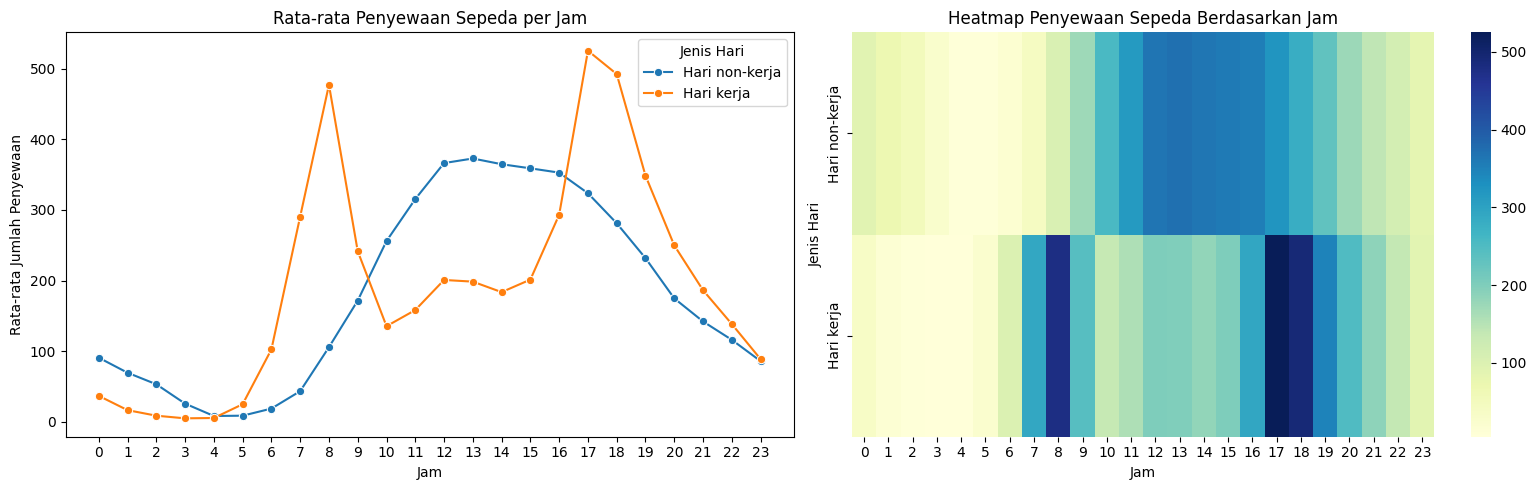

In [7]:
# Menghitung rata-rata penyewaan berdasarkan jam dan jenis hari
hourly_plot = (
    hour_df.groupby(["workingday", "hr"])["cnt"]
    .mean()
    .reset_index()
)

hourly_plot["jenis_hari"] = hourly_plot["workingday"].map({
    0: "Hari non-kerja",
    1: "Hari kerja"
})

# Membuat dua visualisasi
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Visualisasi 1: Line chart
sns.lineplot(
    data=hourly_plot,
    x="hr",
    y="cnt",
    hue="jenis_hari",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Rata-rata Penyewaan Sepeda per Jam")
axes[0].set_xlabel("Jam")
axes[0].set_ylabel("Rata-rata Jumlah Penyewaan")
axes[0].set_xticks(range(24))
axes[0].legend(title="Jenis Hari")

# Visualisasi 2: Heatmap
heatmap_data = (
    hour_df.groupby(["workingday", "hr"])["cnt"]
    .mean()
    .unstack()
)

heatmap_data = heatmap_data.rename(index={
    0: "Hari non-kerja",
    1: "Hari kerja"
})

sns.heatmap(
    heatmap_data,
    cmap="YlGnBu",
    ax=axes[1]
)

axes[1].set_title("Heatmap Penyewaan Sepeda Berdasarkan Jam")
axes[1].set_xlabel("Jam")
axes[1].set_ylabel("Jenis Hari")

plt.tight_layout()
plt.show()

### Pertanyaan 2:

,weathersit,kategori_cuaca,rata_rata_sewa,jumlah_hari,selisih_persen
0,1,Cerah / berawan ringan,4876.79,463,0.00
1,2,Berkabut / berawan,4035.86,247,-17.24
2,3,Hujan / salju ringan,1803.29,21,-63.02


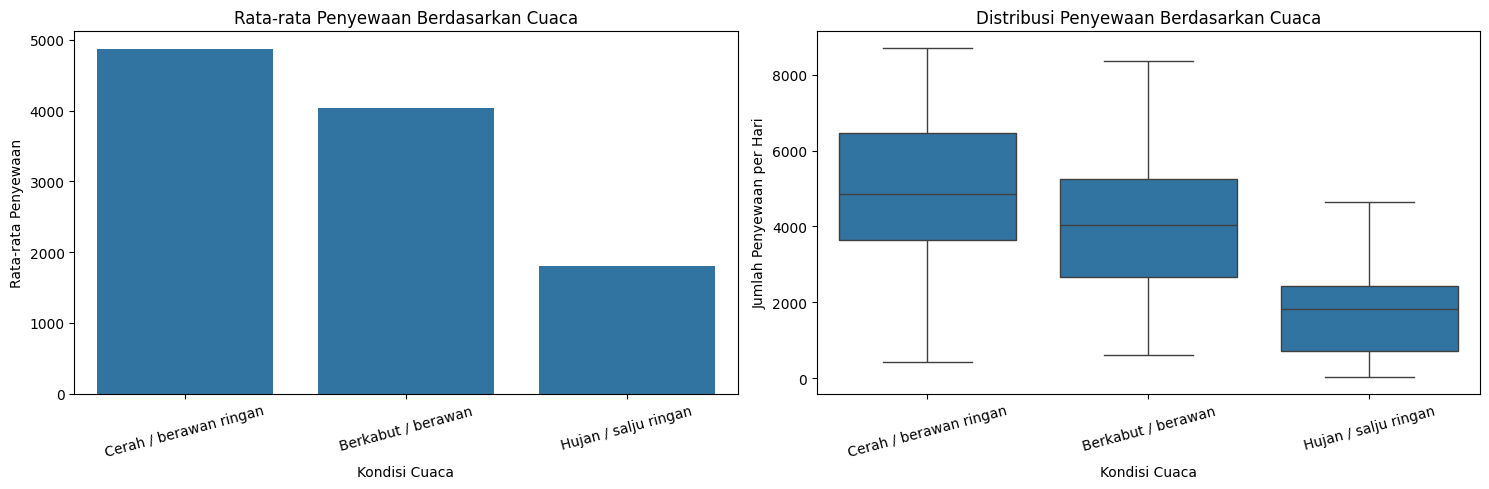

In [8]:
# Memberikan nama pada setiap kategori cuaca
weather_plot = day_df.copy()

weather_labels = {
    1: "Cerah / berawan ringan",
    2: "Berkabut / berawan",
    3: "Hujan / salju ringan",
    4: "Cuaca buruk"
}

weather_plot["kategori_cuaca"] = (
    weather_plot["weathersit"].map(weather_labels)
)

# Menghitung rata-rata penyewaan dan jumlah hari
weather_summary = (
    weather_plot.groupby(
        ["weathersit", "kategori_cuaca"]
    )
    .agg(
        rata_rata_sewa=("cnt", "mean"),
        jumlah_hari=("cnt", "count")
    )
    .reset_index()
)

# Menghitung persentase perbedaan dari kategori cuaca 1
cuaca_cerah = weather_summary.loc[
    weather_summary["weathersit"] == 1,
    "rata_rata_sewa"
].iloc[0]

weather_summary["selisih_persen"] = (
    (weather_summary["rata_rata_sewa"] - cuaca_cerah)
    / cuaca_cerah * 100
)

display(weather_summary.round(2))

# Menentukan urutan kategori cuaca
weather_order = weather_summary["kategori_cuaca"].tolist()

# Membuat dua visualisasi
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Visualisasi 1: Bar chart
sns.barplot(
    data=weather_summary,
    x="kategori_cuaca",
    y="rata_rata_sewa",
    order=weather_order,
    ax=axes[0]
)

axes[0].set_title("Rata-rata Penyewaan Berdasarkan Cuaca")
axes[0].set_xlabel("Kondisi Cuaca")
axes[0].set_ylabel("Rata-rata Penyewaan")
axes[0].tick_params(axis="x", rotation=15)

# Visualisasi 2: Boxplot
sns.boxplot(
    data=weather_plot,
    x="kategori_cuaca",
    y="cnt",
    order=weather_order,
    ax=axes[1]
)

axes[1].set_title("Distribusi Penyewaan Berdasarkan Cuaca")
axes[1].set_xlabel("Kondisi Cuaca")
axes[1].set_ylabel("Jumlah Penyewaan per Hari")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pola penyewaan berdasarkan waktu: Pada hari kerja, jumlah penyewaan rata-rata mencapai puncak pada pukul 17.00, yaitu sekitar 525 penyewaan. Pada hari non-kerja, puncaknya terjadi pada pukul 13.00 dengan rata-rata sekitar 373 penyewaan. Hal ini menunjukkan adanya perbedaan pola penggunaan sepeda berdasarkan jenis hari.
- Pola penyewaan berdasarkan cuaca: Rata-rata penyewaan harian tertinggi terdapat pada kategori cuaca 1, yaitu sekitar 4.877 penyewaan. Dibandingkan kategori tersebut, rata-rata penyewaan pada kategori cuaca 2 lebih rendah sekitar 17,24%, sedangkan kategori cuaca 3 lebih rendah sekitar 63,02%.

## Analisis Lanjutan (Opsional)

,workingday,kelompok_waktu,casual,registered,jenis_hari
0,0,Dini hari,8.39,34.61,Hari non-kerja
1,0,Pagi,19.50,65.50,Hari non-kerja
2,0,Siang,120.78,218.16,Hari non-kerja
3,0,Sore,97.60,199.74,Hari non-kerja
4,0,Malam,32.53,97.17,Hari non-kerja
5,1,Dini hari,2.69,13.74,Hari kerja
6,1,Pagi,15.77,262.14,Hari kerja
7,1,Siang,40.83,138.83,Hari kerja
8,1,Sore,49.18,365.57,Hari kerja
9,1,Malam,22.23,143.54,Hari kerja


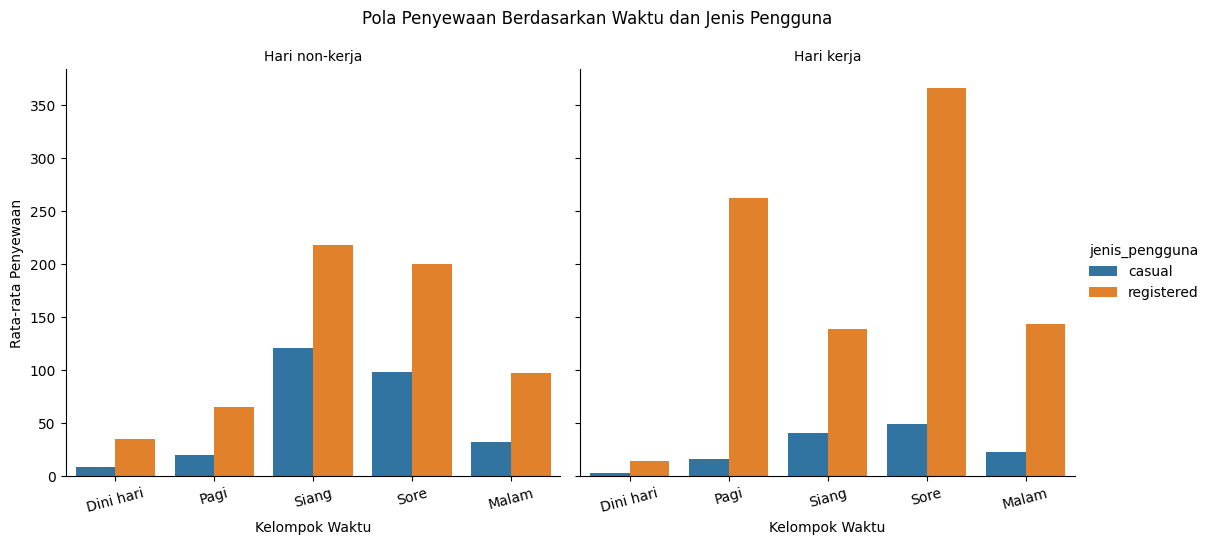

In [9]:
# Mengelompokkan jam penyewaan menjadi beberapa periode waktu
hour_df["kelompok_waktu"] = pd.cut(
    hour_df["hr"],
    bins=[-1, 5, 9, 15, 19, 23],
    labels=[
        "Dini hari",
        "Pagi",
        "Siang",
        "Sore",
        "Malam"
    ]
)

# Menghitung rata-rata penyewaan berdasarkan jenis pengguna
advanced_summary = (
    hour_df.groupby(
        ["workingday", "kelompok_waktu"],
        observed=True
    )
    .agg(
        casual=("casual", "mean"),
        registered=("registered", "mean")
    )
    .reset_index()
)

# Mengubah kode jenis hari menjadi label
advanced_summary["jenis_hari"] = (
    advanced_summary["workingday"]
    .map({
        0: "Hari non-kerja",
        1: "Hari kerja"
    })
)

# Menampilkan hasil analisis
display(advanced_summary.round(2))

# Mengubah tabel agar mudah dibuat grafik
plot_data = advanced_summary.melt(
    id_vars=["jenis_hari", "kelompok_waktu"],
    value_vars=["casual", "registered"],
    var_name="jenis_pengguna",
    value_name="rata_rata_penyewaan"
)

# Membuat visualisasi
g = sns.catplot(
    data=plot_data,
    x="kelompok_waktu",
    y="rata_rata_penyewaan",
    hue="jenis_pengguna",
    col="jenis_hari",
    kind="bar",
    height=5,
    aspect=1.1
)

g.set_axis_labels("Kelompok Waktu", "Rata-rata Penyewaan")
g.set_titles("{col_name}")
g.set_xticklabels(rotation=15)
g.fig.suptitle(
    "Pola Penyewaan Berdasarkan Waktu dan Jenis Pengguna",
    y=1.05
)

plt.show()

**Insight:** (Opsional)
- Pada hari non-kerja, rata-rata penyewaan kedua jenis pengguna mencapai nilai tertinggi pada siang hari. Pengguna kasual memiliki rata-rata sekitar 120,78 penyewaan per jam, sedangkan pengguna terdaftar sekitar 218,16 penyewaan per jam.
- Pada hari kerja, rata-rata penyewaan kedua jenis pengguna mencapai nilai tertinggi pada sore hari. Pengguna kasual memiliki rata-rata sekitar 49,18 penyewaan per jam, sedangkan pengguna terdaftar sekitar 365,57 penyewaan per jam.
- Pengguna terdaftar memiliki rata-rata penyewaan lebih tinggi dibandingkan pengguna kasual pada seluruh kelompok waktu yang dianalisis.
- Hasil ini menunjukkan bahwa pola penyewaan berbeda antara hari kerja dan hari non-kerja. Informasi tersebut dapat digunakan untuk membantu memperkirakan kebutuhan sepeda pada waktu yang berbeda.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan hasil analisis, pola penyewaan sepeda berbeda antara hari kerja dan hari non-kerja selama Januari 2011 hingga Desember 2012. Pada hari kerja, rata-rata penyewaan tertinggi terjadi pada pukul 17.00 dengan sekitar 525 penyewaan per jam. Sementara itu, pada hari non-kerja, rata-rata penyewaan tertinggi terjadi pada pukul 13.00 dengan sekitar 373 penyewaan per jam. Hasil ini menunjukkan bahwa waktu dengan permintaan tertinggi berbeda berdasarkan jenis hari.
- **Conclusion pertanyaan 2:** Hasil analisis menunjukkan bahwa rata-rata penyewaan sepeda harian tertinggi terdapat pada kategori cuaca 1, yaitu sekitar 4.877 penyewaan. Pada kategori cuaca 2, rata-rata penyewaan turun sekitar 17,24%, sedangkan pada kategori cuaca 3 turun sekitar 63,02% dibandingkan kategori cuaca 1. Hal ini menunjukkan adanya perbedaan jumlah penyewaan pada setiap kategori cuaca. Namun, hasil ini belum membuktikan bahwa cuaca merupakan satu-satunya faktor yang memengaruhi jumlah penyewaan.

**Rekomendasi Action Item:**
- **Menyesuaikan ketersediaan sepeda berdasarkan waktu:** Pengelola dapat meningkatkan kesiapan armada menjelang pukul 17.00 pada hari kerja dan pukul 13.00 pada hari non-kerja untuk mengantisipasi peningkatan permintaan.
- **Mempertimbangkan kondisi cuaca:** Pengelola dapat menggunakan prakiraan cuaca sebagai salah satu pertimbangan dalam merencanakan ketersediaan sepeda. Karena jumlah penyewaan berbeda pada setiap kategori cuaca, perencanaan operasional perlu disesuaikan dengan perkiraan kondisi cuaca.
- **Memperhatikan perbedaan jenis pengguna:** Berdasarkan analisis lanjutan, pengguna terdaftar memiliki rata-rata penyewaan lebih tinggi daripada pengguna kasual pada seluruh kelompok waktu. Pengelola dapat menggunakan informasi ini untuk memahami kebutuhan pengguna dan menyusun strategi promosi yang sesuai.
- **Melakukan evaluasi berkala:** Pengelola perlu memantau data penyewaan secara berkala untuk mengetahui apakah pola permintaan tetap sama atau berubah dari waktu ke waktu.